In [20]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

df = pd.read_csv("battery_observations.csv", index_col=0)
meta = pd.read_csv("battery_metadata.csv", index_col=0)
df2 = df.join(meta[["climate_zone", "chemistry", "usage_strategy"]])
df2 = df2.sort_values(["battery_id", "cycle_index"])
df2 = df2.reset_index()
meta = meta.reset_index()
g = lambda x: int(x.split('-')[-1])
df2["battery_id"] = df2["battery_id"].apply(g)
meta["battery_id"] = meta["battery_id"].apply(g)
battery_ids = list(set(df2["battery_id"]))
materials = list(set(meta["chemistry"]))
climate_zones = list(set(meta["climate_zone"]))
labels = list(set(df2["degradation_status"]))
usage_strategies = list(set(df2["usage_strategy"]))

In [11]:
nonnormal = df2[df2["degradation_status"] != "Normal"]
x = nonnormal.groupby("battery_id").agg(
    min_cycle_idx=("cycle_index", "min"),
    age_when_reached=("battery_age_days", "min"),
    mean_ambient_temp=("ambient_temp_c", "mean"),
    mean_pack_temp=("pack_temp_c", "mean"), 
    high_temp_hours_before=("cumulative_high_temp_hours", "min"),
    mean_charge=("charge_c_rate", "mean"),
    mean_discharge=("discharge_c_rate", "mean"),
    mean_cooling_active=("cooling_active", "mean")
)
print(x)

            min_cycle_idx  age_when_reached  mean_ambient_temp  \
battery_id                                                       
1                     347             625.2          14.406047   
2                     289             512.9           4.547577   
3                     202             352.7          24.055802   
4                     225             412.2           4.987719   
5                     330             601.2           4.619025   
...                   ...               ...                ...   
196                   231             394.9           3.497572   
197                   575            1038.3          14.480087   
198                   420             774.7          25.452279   
199                   155             270.1          24.684404   
200                   615            1090.2          28.077257   

            mean_pack_temp  high_temp_hours_before  mean_charge  \
battery_id                                                        
1      

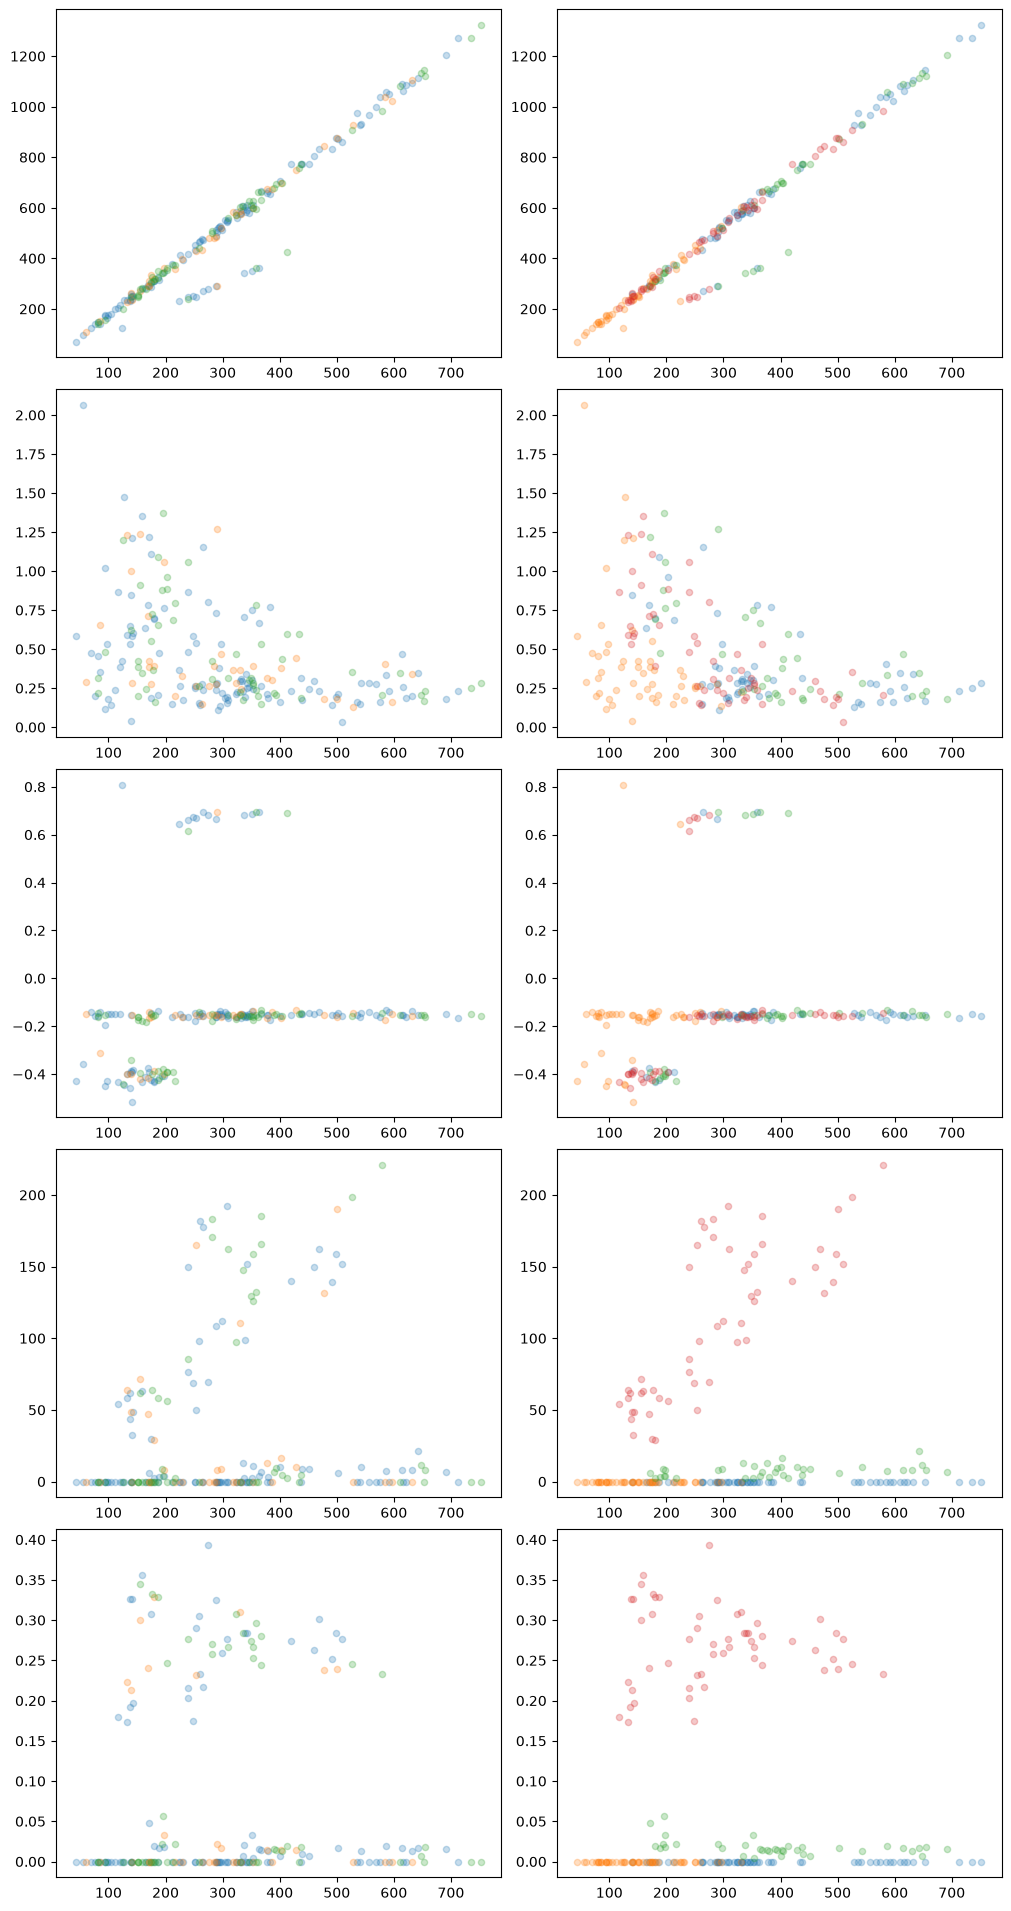

In [18]:
nrows, ncols = 5, 2
fig, axes = plt.subplots(
    nrows,
    ncols,
    figsize=(5 * ncols, 3.8 * nrows),
    layout="constrained",
    squeeze=False
)
colors = [f"C{k}" for k in range(len(materials))]
for i,m in enumerate(materials):
    z = meta.loc[meta["chemistry"] == m, "battery_id"]
    y = x[x.index.isin(z)]
    axes[0,0].scatter(y["min_cycle_idx"], y["age_when_reached"], color=colors[i], s=20, alpha=0.25,)
    axes[1,0].scatter(y["min_cycle_idx"], y["mean_pack_temp"] - y["mean_ambient_temp"], color=colors[i], s=20, alpha=0.25,)
    axes[2,0].scatter(y["min_cycle_idx"], y["mean_charge"] - y["mean_discharge"], color=colors[i], s=20, alpha=0.25,)
    axes[3,0].scatter(y["min_cycle_idx"], y["high_temp_hours_before"], color=colors[i], s=20, alpha=0.25,)
    axes[4,0].scatter(y["min_cycle_idx"], y["mean_cooling_active"], color=colors[i], s=20, alpha=0.25,)

colors = [f"C{k}" for k in range(len(climate_zones))]
for i,m in enumerate(climate_zones):
    z = meta.loc[meta["climate_zone"] == m, "battery_id"]
    y = x[x.index.isin(z)]
    axes[0,1].scatter(y["min_cycle_idx"], y["age_when_reached"], color=colors[i], s=20, alpha=0.25,)
    axes[1,1].scatter(y["min_cycle_idx"], y["mean_pack_temp"] - y["mean_ambient_temp"], color=colors[i], s=20, alpha=0.25,)
    axes[2,1].scatter(y["min_cycle_idx"], y["mean_charge"] - y["mean_discharge"], color=colors[i], s=20, alpha=0.25,)
    axes[3,1].scatter(y["min_cycle_idx"], y["high_temp_hours_before"], color=colors[i], s=20, alpha=0.25,)
    axes[4,1].scatter(y["min_cycle_idx"], y["mean_cooling_active"], color=colors[i], s=20, alpha=0.25,)

plt.show()

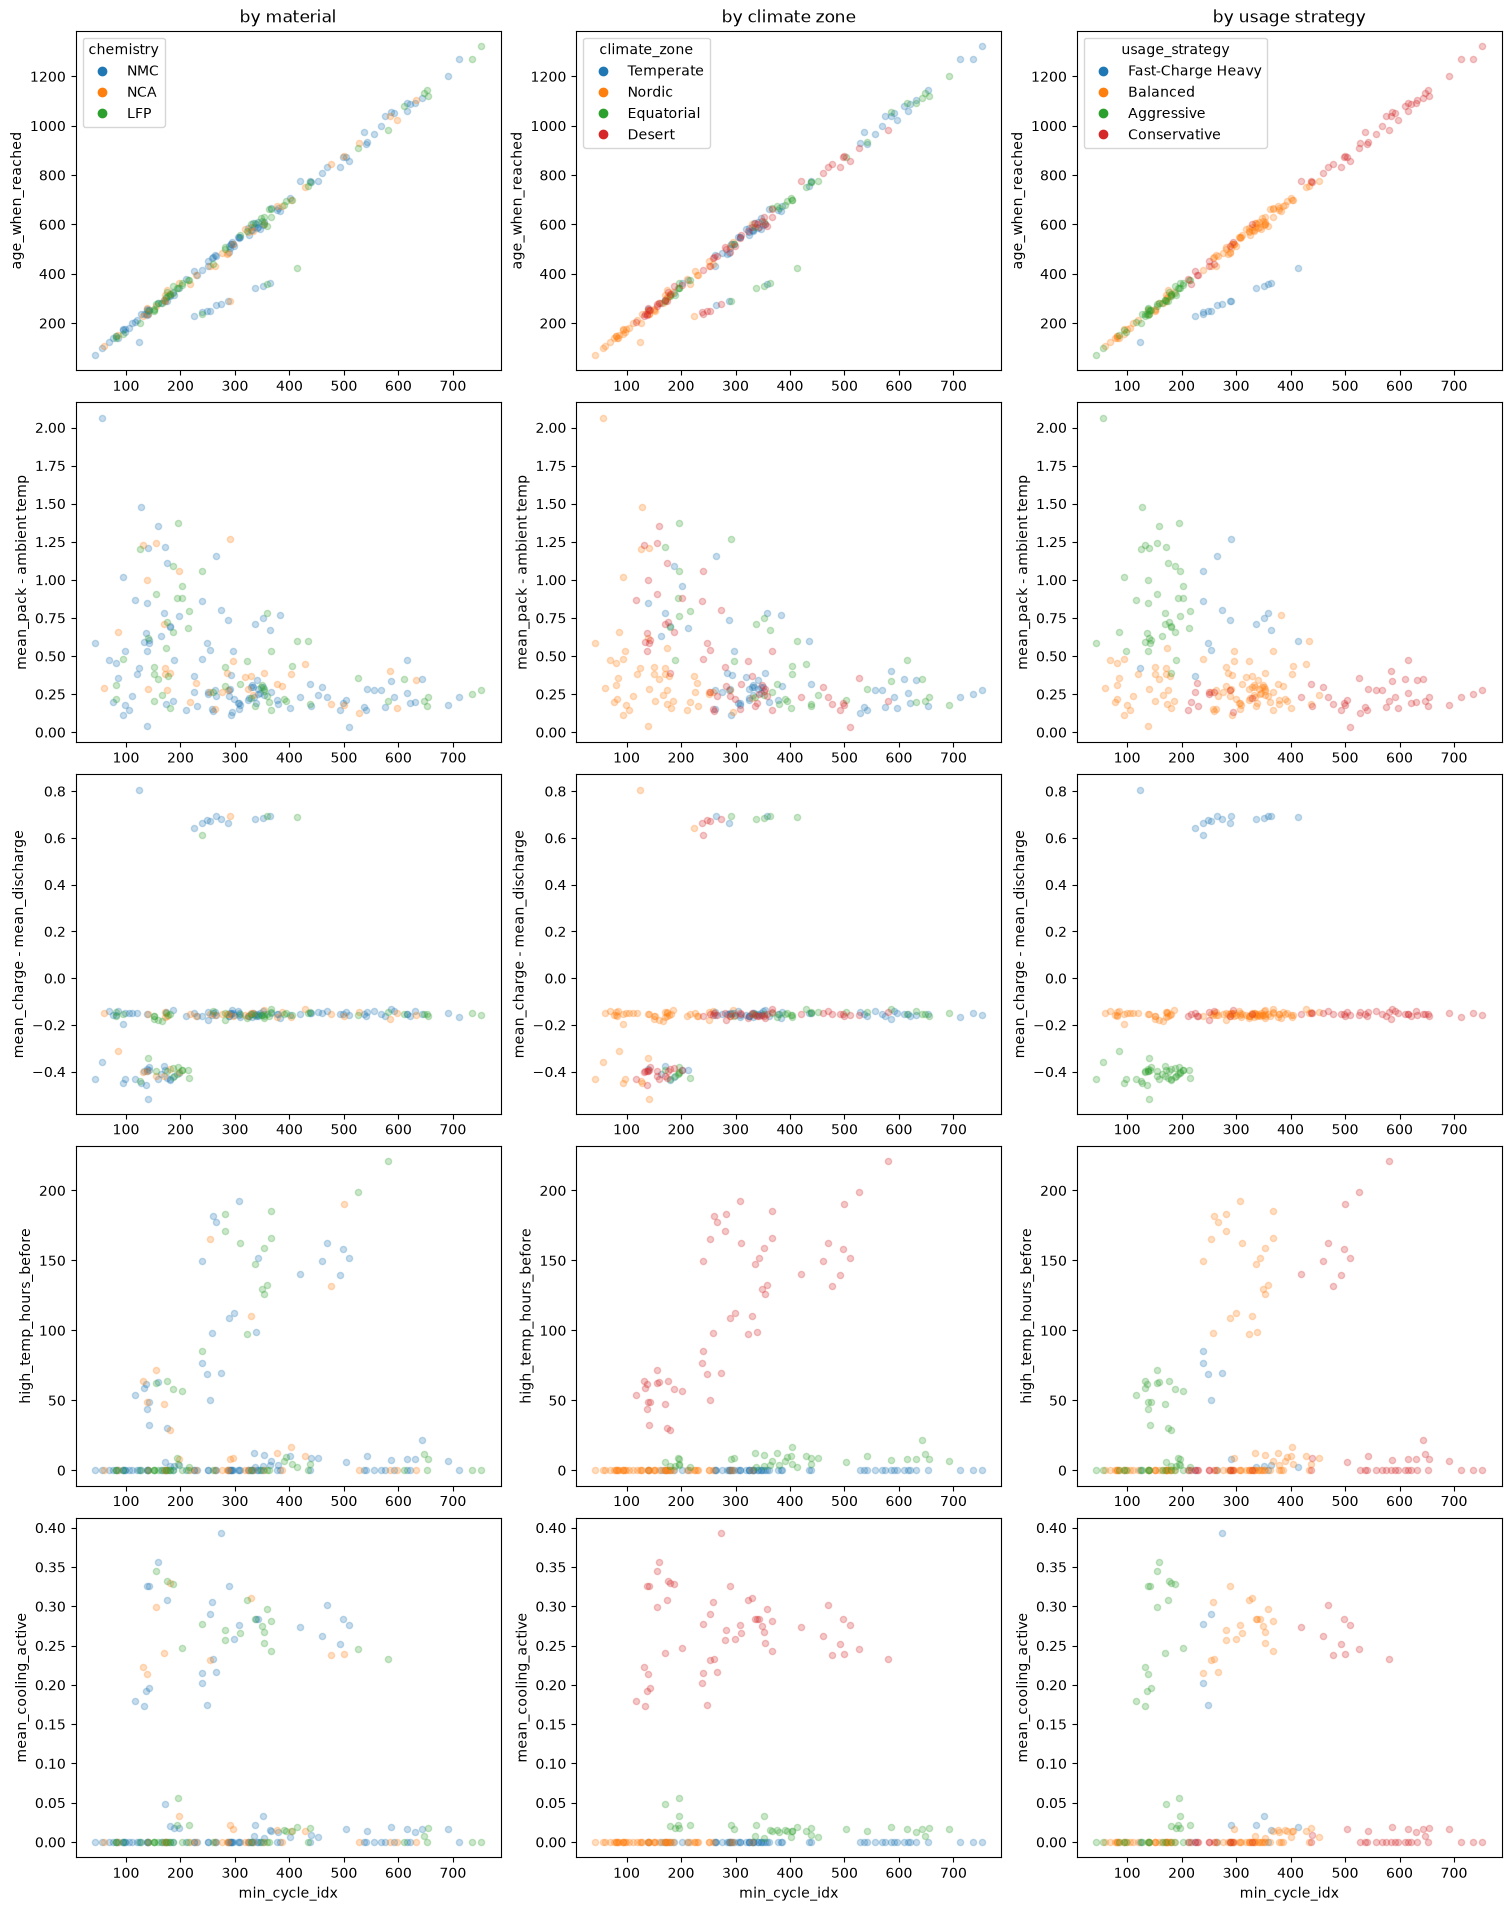

In [22]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# what to plot in each row: (y-label, function computing y from the group's rows)
metrics = [
    ("age_when_reached",           lambda d: d["age_when_reached"]),
    ("mean_pack - ambient temp",   lambda d: d["mean_pack_temp"] - d["mean_ambient_temp"]),
    ("mean_charge - mean_discharge", lambda d: d["mean_charge"] - d["mean_discharge"]),
    ("high_temp_hours_before",     lambda d: d["high_temp_hours_before"]),
    ("mean_cooling_active",        lambda d: d["mean_cooling_active"]),
]

# one entry per column: (meta column to group by, groups, title)
columns = [
    ("chemistry",    materials,     "by material"),
    ("climate_zone", climate_zones, "by climate zone"),
    ("usage_strategy", usage_strategies, "by usage strategy")
]

nrows, ncols = len(metrics), len(columns)
fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 3.8 * nrows),
                         layout="constrained", squeeze=False)

for j, (meta_col, groups, title) in enumerate(columns):
    color_map = {g: f"C{k}" for k, g in enumerate(groups)}

    for g in groups:
        ids = meta.loc[meta[meta_col] == g, "battery_id"]
        y = x[x.index.isin(ids)]
        for i, (ylabel, fn) in enumerate(metrics):
            axes[i, j].scatter(y["min_cycle_idx"], fn(y),
                               color=color_map[g], s=20, alpha=0.25)

    # axis labels and titles
    axes[0, j].set_title(title)
    for i, (ylabel, _) in enumerate(metrics):
        axes[i, j].set_ylabel(ylabel)
    axes[-1, j].set_xlabel("min_cycle_idx")

    # legend on the top plot of each column (full-opacity handles, since points are faint)
    handles = [Line2D([0], [0], marker="o", linestyle="none", color=c, label=str(g))
               for g, c in color_map.items()]
    axes[0, j].legend(handles=handles, title=meta_col, loc="best")

plt.show()

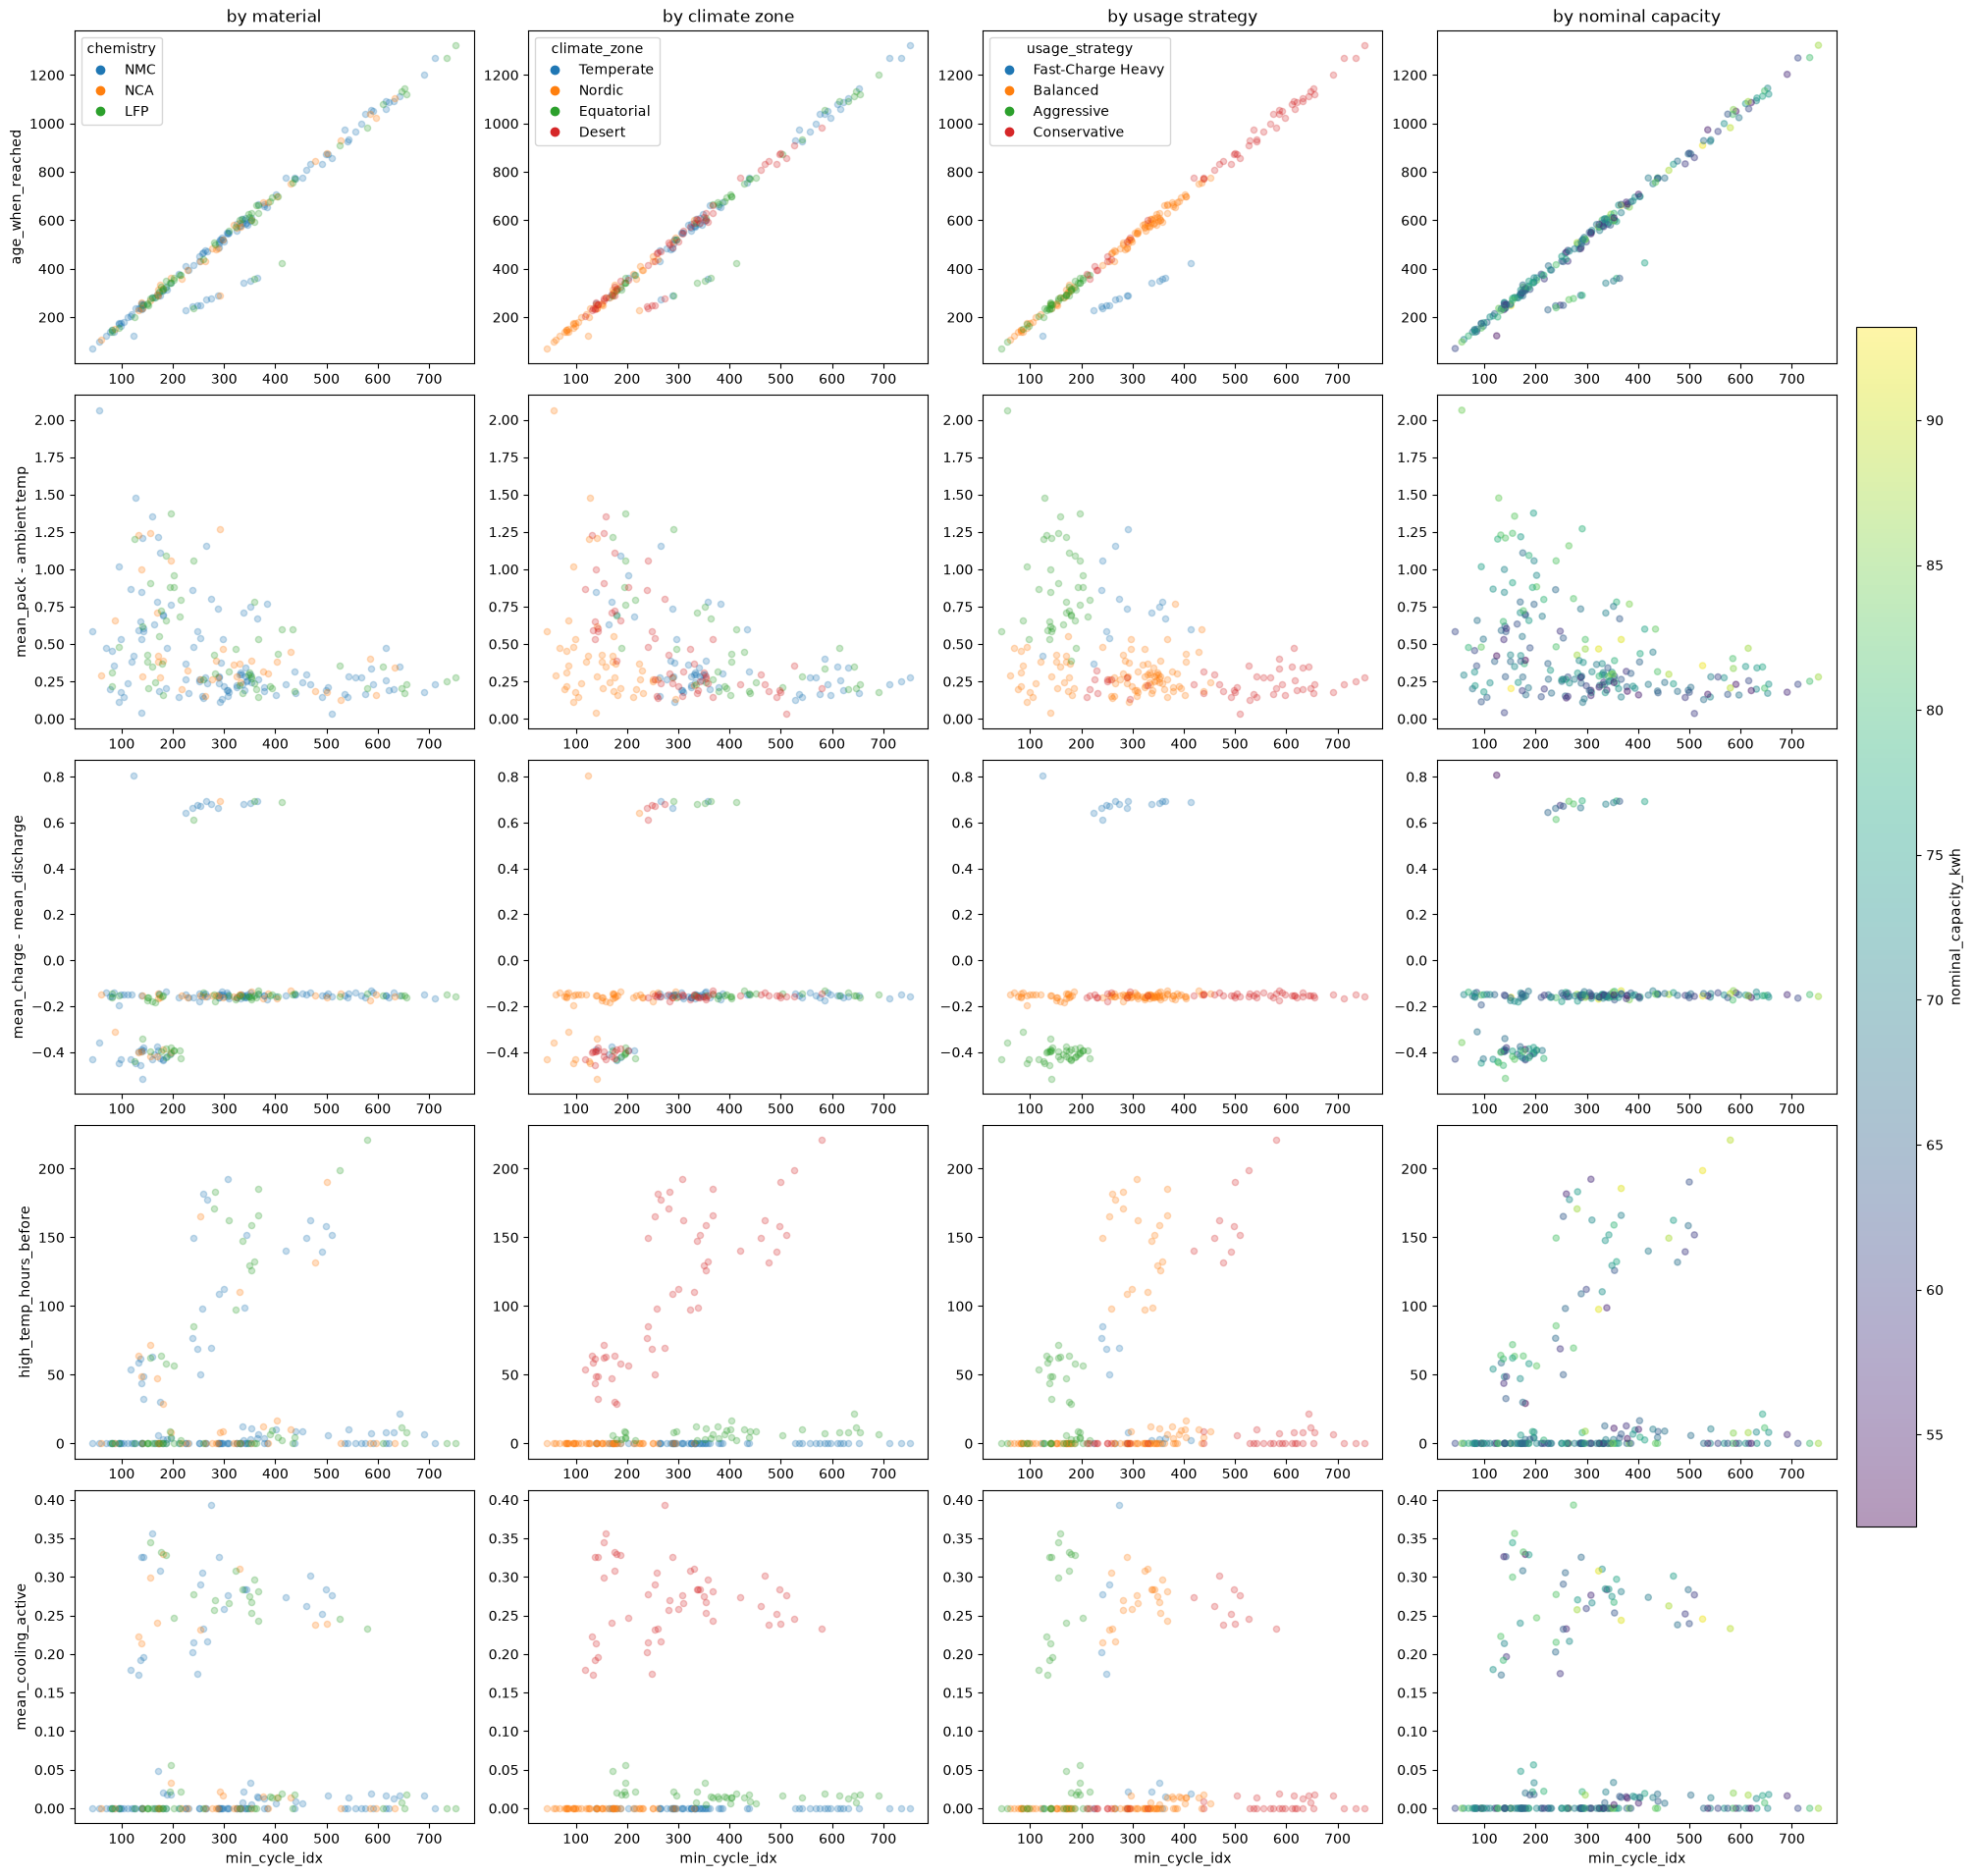

In [23]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

metrics = [
    ("age_when_reached",             lambda d: d["age_when_reached"]),
    ("mean_pack - ambient temp",     lambda d: d["mean_pack_temp"] - d["mean_ambient_temp"]),
    ("mean_charge - mean_discharge", lambda d: d["mean_charge"] - d["mean_discharge"]),
    ("high_temp_hours_before",       lambda d: d["high_temp_hours_before"]),
    ("mean_cooling_active",          lambda d: d["mean_cooling_active"]),
]

# categorical columns: (meta column, groups, title)
columns = [
    ("chemistry",      materials,        "by material"),
    ("climate_zone",   climate_zones,    "by climate zone"),
    ("usage_strategy", usage_strategies, "by usage strategy"),
]

nrows = len(metrics)
ncols = len(columns) + 1          # +1 for the continuous capacity column
fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 3.8 * nrows),
                         layout="constrained", squeeze=False)

# --- categorical columns: one color per group, with legend ---
for j, (meta_col, groups, title) in enumerate(columns):
    color_map = {g: f"C{k}" for k, g in enumerate(groups)}

    for g in groups:
        ids = meta.loc[meta[meta_col] == g, "battery_id"]
        y = x[x.index.isin(ids)]
        for i, (ylabel, fn) in enumerate(metrics):
            axes[i, j].scatter(y["min_cycle_idx"], fn(y),
                               color=color_map[g], s=20, alpha=0.25)

    axes[0, j].set_title(title)
    handles = [Line2D([0], [0], marker="o", linestyle="none", color=c, label=str(g))
               for g, c in color_map.items()]
    axes[0, j].legend(handles=handles, title=meta_col, loc="best")

# --- last column: continuous nominal capacity, colormap + colorbar ---
j = ncols - 1
capacity = meta.set_index("battery_id")["nominal_capacity_kwh"]
cap = x.index.map(capacity)                      # capacity of each row's battery (x is indexed by battery_id)
vmin, vmax = capacity.min(), capacity.max()      # same color scale in every row

for i, (ylabel, fn) in enumerate(metrics):
    sc = axes[i, j].scatter(x["min_cycle_idx"], fn(x), c=cap, cmap="viridis",
                            vmin=vmin, vmax=vmax, s=20, alpha=0.4)

axes[0, j].set_title("by nominal capacity")
fig.colorbar(sc, ax=axes[:, j], label="nominal_capacity_kwh", shrink=0.8)

# --- labels shared by all columns ---
for j in range(ncols):
    axes[-1, j].set_xlabel("min_cycle_idx")
for i, (ylabel, _) in enumerate(metrics):
    axes[i, 0].set_ylabel(ylabel)

plt.show()